# Amen's XAUUSD bot: indicator review, backtest and stress test

Strategy under test (`bot_mt5.py`): XAUUSD M5, trend = EMA20 vs EMA50 with price on the right side of
EMA50 and EMA gap >= 0.2 ATR, entry when RSI(14) crosses back above 45 (buy) or below 55 (sell) on a
closed bar, SL = 1.0 ATR, TP = 1.5 ATR, plus the bot's money rules (180 max daily loss, 2 trades/day,
600 weekly target, 2 positions max).

Data: HistData.com XAUUSD M1 bid quotes, Jan 2022 to Nov 2026 (about 4.9 years, 1.68M M1 bars, New York local stamps converted to UTC),
resampled to M5. Exits are resolved on the M1 bars so the order of SL/TP hits inside a 5 minute candle
is known, not guessed.

Sections
1. Data and engine validation (the engine reproduces the bot's own code exactly)
2. Faithful replay of the bot with its money rules
3. Raw edge of the entry signal, cost sensitivity, random-entry benchmark
4. Permutation test (Monte Carlo null distribution)
5. Where it wins and loses (year, side, session, volatility, trend strength)
6. Parameter sensitivity surfaces
7. Walk-forward optimisation
8. Monte Carlo on the trade sequence (drawdown and ruin risk)
9. Stress tests
10. Probabilistic and Deflated Sharpe
11. Gaps found in the indicator and the code
12. Improvement research with an untouched holdout
13. Conclusions

In [1]:
import sys, types, time, warnings
warnings.filterwarnings("ignore")
fake = types.ModuleType("MetaTrader5"); fake.TIMEFRAME_M5 = 5
sys.modules.setdefault("MetaTrader5", fake)
sys.path.insert(0, "..")
import bot_mt5 as bot
import engine as E
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# chart styling: one categorical order, recessive grid, diverging map with a gray midpoint
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
GRID, INK, MUTED = "#e3e2de", "#0b0b0b", "#52514e"
DIV = LinearSegmentedColormap.from_list("div", [C2, "#efeeea", C1])
plt.rcParams.update({"figure.figsize": (11, 4.2), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False})
SPREAD = 0.30   # USD per oz, typical retail XAUUSD spread (bot rejects > 0.50)
P0 = E.Params()
rng = np.random.default_rng(42)

## 1. Data and engine validation

In [2]:
m1 = E.load_m1()
m5 = E.resample(m1)
ind = E.add_htf(E.indicators(m5, P0), m1)
ex = E.ExitSolver(m1)
print(f"M1 bars: {len(m1):,}  from {m1.time.min()} to {m1.time.max()} UTC")
print(f"M5 bars: {len(m5):,}")
cov = m5.groupby(m5.time.dt.year).agg(bars=("close", "size"), first=("time", "min"), last=("time", "max"))
cov["median_M5_ATR"] = ind.groupby(ind.time.dt.year)["atr"].median().round(2)
cov["median_price"] = m5.groupby(m5.time.dt.year)["close"].median().round(0)
cov

M1 bars: 1,682,112  from 2022-01-02 23:00:00 to 2026-11-13 21:58:00 UTC
M5 bars: 336,526


,bars,first,last,median_M5_ATR,median_price
time,,,,,
2022,70928,2022-01-02 23:00:00,2022-12-30 21:55:00,1.16,1804.0
2023,61794,2023-01-02 23:00:00,2023-12-29 21:55:00,1.01,1941.0
2024,71133,2024-01-01 23:00:00,2024-12-31 21:55:00,1.48,2381.0
2025,70810,2025-01-01 23:00:00,2025-12-31 21:55:00,2.76,3345.0
2026,61861,2026-01-01 23:00:00,2026-11-13 21:55:00,5.04,4441.0


In [3]:
# The engine must reproduce bot_mt5.compute_indicators and bot_mt5.get_signal exactly
ref = bot.compute_indicators(m5[["time", "open", "high", "low", "close"]].copy())
same_ind = np.allclose(ref[["ema_fast", "ema_slow", "rsi", "atr"]].values,
                       ind[["ema_fast", "ema_slow", "rsi", "atr"]].values, equal_nan=True)
sig0 = E.signals(ind, P0, SPREAD)
sample = rng.integers(100, len(ind), 20000)
bot_sig = np.array([{"BUY": 1, "SELL": -1, None: 0}[bot.get_signal(ind.iloc[i], ind.iloc[i - 1])[0]] for i in sample])
print("indicators identical to bot code:", same_ind)
print("signal mismatches vs bot.get_signal on 20,000 random bars:", int((bot_sig != sig0[sample]).sum()))
print(f"signals over the full period: {(sig0 != 0).sum():,}  (buy {(sig0 == 1).sum():,}, sell {(sig0 == -1).sum():,})")

indicators identical to bot code: True
signal mismatches vs bot.get_signal on 20,000 random bars: 0
signals over the full period: 5,670  (buy 3,014, sell 2,656)


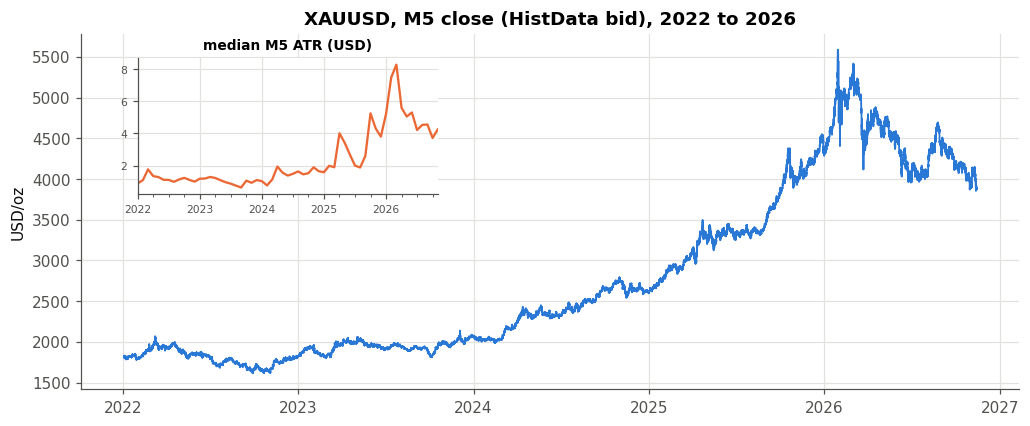

In [4]:
fig, ax = plt.subplots()
ax.plot(m5.time, m5.close, color=C1, lw=1.2)
ax.set_title("XAUUSD, M5 close (HistData bid), 2022 to 2026"); ax.set_ylabel("USD/oz")
ax2 = ax.inset_axes([0.06, 0.55, 0.32, 0.38])
ind.groupby(ind.time.dt.to_period("M"))["atr"].median().plot(ax=ax2, color=C2, lw=1.5)
ax2.set_title("median M5 ATR (USD)", fontsize=9); ax2.set_xlabel(""); ax2.tick_params(labelsize=7)
plt.show()

## 2. Faithful replay of the bot with its money rules

100,000 demo account (as in `bot.log`), spread 0.30, every rule of `bot_mt5.py` replayed: daily loss
budget 180 (worst case incl. open risk), max 2 trades per day, weekly realised target 600, 2 positions,
no opposite positions, close-all when the daily limit is hit, lot sizing `min(0.5% equity, budget / trades left)`.
The Gemini filter cannot be backtested (non-deterministic LLM call) and is left out.

In [5]:
t0 = time.time()
bt, end_eq = E.run_bot(ind, sig0, ex, P0, spread=SPREAD)
print(f"replay took {time.time()-t0:.1f}s")
s = E.summary(bt, "pnl")
print(f"trades {s['trades']}, win rate {s['win_pct']:.1f}%, avg PnL {s['avg']:.1f} USD, total {s['total']:,.0f} USD, "
      f"profit factor {s['pf']:.2f}, max drawdown {s['max_dd']:,.0f} USD, final equity {end_eq:,.0f}")
print(f"average risk per trade {bt.risk.mean():.0f} USD ({bt.risk.mean()/1000:.2f}% of 100k), average lots {bt.lots.mean():.2f}")
print("exit reasons:", bt.why.value_counts().to_dict())

replay took 2.9s
trades 2380, win rate 30.8%, avg PnL -22.8 USD, total -54,177 USD, profit factor 0.67, max drawdown -54,993 USD, final equity 45,823
average risk per trade 100 USD (0.10% of 100k), average lots 0.77
exit reasons: {'sl': 1645, 'tp': 733, 'sl-ambig': 2}


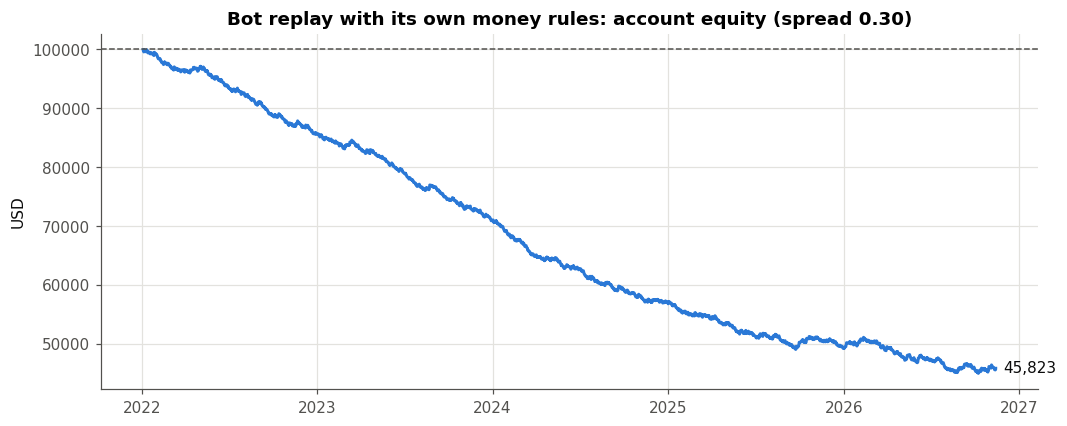

,trades,win_pct,pnl_usd,avg_R
exit_time,,,,
2022,506,27.67,-14394.54,-0.31
2023,477,25.58,-14722.11,-0.35
2024,486,28.81,-14102.43,-0.28
2025,486,34.98,-7454.33,-0.13
2026,425,37.88,-3503.43,-0.05


In [6]:
eq = 100_000 + bt.pnl.cumsum()
fig, ax = plt.subplots()
ax.plot(bt.exit_time, eq, color=C1)
ax.axhline(100_000, color=MUTED, lw=1, ls="--")
ax.set_title("Bot replay with its own money rules: account equity (spread 0.30)")
ax.set_ylabel("USD"); ax.annotate(f"{eq.iloc[-1]:,.0f}", (bt.exit_time.iloc[-1], eq.iloc[-1]), color=INK,
                                  xytext=(5, 0), textcoords="offset points", va="center")
plt.show()
yr = bt.groupby(bt.exit_time.dt.year).agg(trades=("pnl", "size"), win_pct=("pnl", lambda x: 100 * (x > 0).mean()),
                                          pnl_usd=("pnl", "sum"), avg_R=("R", "mean")).round(2)
yr

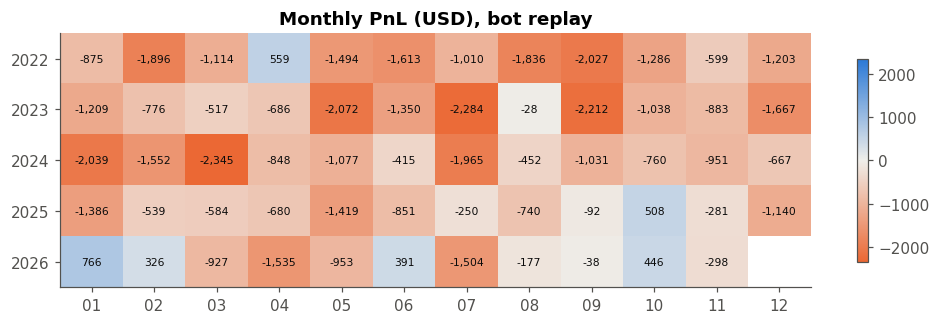

losing months: 53 of 59


In [7]:
mon = bt.groupby([bt.exit_time.dt.year, bt.exit_time.dt.month])["pnl"].sum().unstack()
fig, ax = plt.subplots(figsize=(11, 3))
lim = np.nanmax(np.abs(mon.values))
im = ax.imshow(mon.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(mon.shape[1]), [f"{m:02d}" for m in mon.columns]); ax.set_yticks(range(mon.shape[0]), mon.index)
for (r, c), v in np.ndenumerate(mon.values):
    if not np.isnan(v): ax.text(c, r, f"{v:,.0f}", ha="center", va="center", fontsize=7, color=INK)
ax.grid(False); ax.set_title("Monthly PnL (USD), bot replay"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print(f"losing months: {(mon < 0).sum().sum()} of {mon.notna().sum().sum()}")

## 3. Raw edge of the entry signal

The money rules only scale bets; they cannot create an edge. Here every signal is taken (one position
at a time) and measured in R (1R = the SL distance). With SL 1 ATR and TP 1.5 ATR the break-even win
rate is 40% before costs.

In [8]:
raw = E.run_raw(ind, sig0, ex, P0, spread=SPREAD)
raw0 = E.run_raw(ind, sig0, ex, P0, spread=0.0)
rows = []
for sp in [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    sm = E.summary(E.run_raw(ind, sig0, ex, P0, spread=sp)); sm["spread"] = sp; rows.append(sm)
cost = pd.DataFrame(rows).set_index("spread")
cost[["trades", "win_pct", "avg", "total", "pf", "t_stat"]].round(3)

,trades,win_pct,avg,total,pf,t_stat
spread,,,,,,
0.00,4936,40.174,0.005,26.743,1.009,0.306
0.05,4971,38.865,-0.027,-135.967,0.956,-1.558
0.10,5021,37.184,-0.070,-352.396,0.889,-4.051
0.15,5051,35.716,-0.107,-538.911,0.835,-6.231
0.20,5090,34.361,-0.141,-716.568,0.787,-8.336
0.30,5171,31.387,-0.216,-1115.309,0.687,-13.166
0.40,5230,28.948,-0.277,-1449.069,0.612,-17.399
0.50,5284,26.173,-0.347,-1832.508,0.532,-22.688


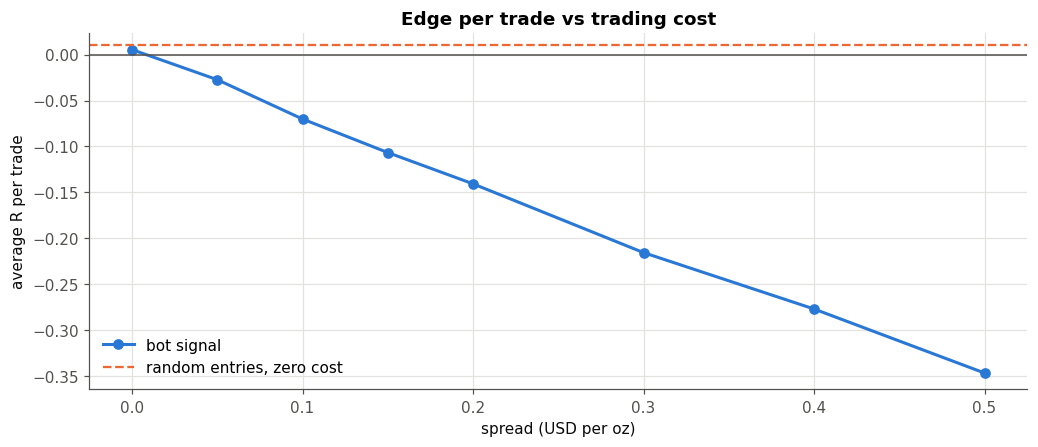

bot signal, zero cost: {'trades': 4936, 'win_pct': 40.174, 'avg': 0.005, 'total': 26.743, 'pf': 1.009, 'max_dd': -83.584, 't_stat': 0.306}
random,     zero cost: {'trades': 7292, 'win_pct': 40.51, 'avg': 0.01, 'total': 74.841, 'pf': 1.017, 'max_dd': -114.305, 't_stat': 0.688}
random,     spread .30: {'trades': 7349, 'win_pct': 32.413, 'avg': -0.191, 'total': -1406.354, 'pf': 0.72, 'max_dd': -1442.524, 't_stat': -13.492}
median spread / SL distance for bot trades: 18.6%


In [9]:
# random entries: same bars universe, random direction, same SL/TP rules
def random_sig(n, seed):
    r = np.random.default_rng(seed); s = np.zeros(len(ind), int)
    pick = r.choice(np.arange(200, len(ind) - 1), n, replace=False); s[pick] = r.choice([-1, 1], n); return s
rnd0 = E.run_raw(ind, random_sig(8000, 1), ex, P0, spread=0.0)
rnd = E.run_raw(ind, random_sig(8000, 1), ex, P0, spread=SPREAD)
fig, ax = plt.subplots()
ax.plot(cost.index, cost["avg"], color=C1, marker="o", ms=6, label="bot signal")
ax.axhline(E.summary(rnd0)["avg"], color=C2, ls="--", lw=1.5, label="random entries, zero cost")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("spread (USD per oz)"); ax.set_ylabel("average R per trade")
ax.set_title("Edge per trade vs trading cost"); ax.legend(); plt.show()
print("bot signal, zero cost:", {k: round(v, 3) for k, v in E.summary(raw0).items()})
print("random,     zero cost:", {k: round(v, 3) for k, v in E.summary(rnd0).items()})
print("random,     spread .30:", {k: round(v, 3) for k, v in E.summary(rnd).items()})
print(f"median spread / SL distance for bot trades: {(SPREAD / raw.sl_dist).median():.1%}")

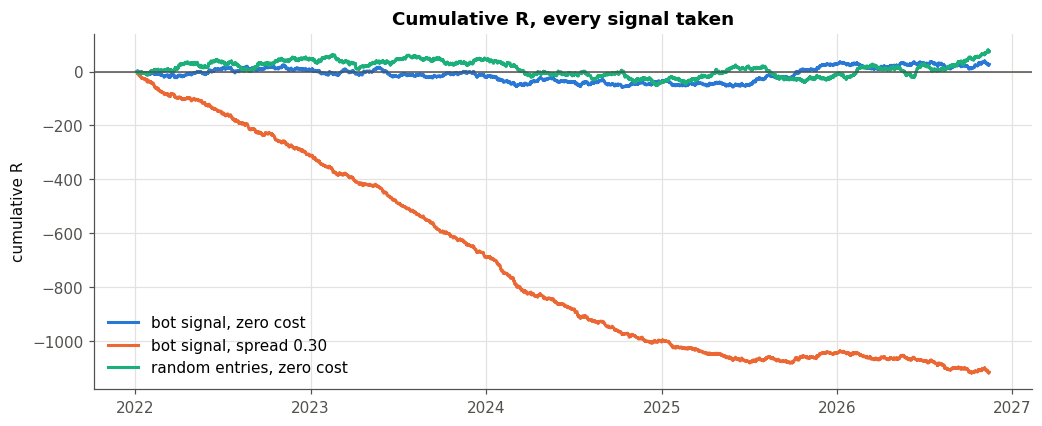

In [10]:
fig, ax = plt.subplots()
for tr, lab, col in [(raw0, "bot signal, zero cost", C1), (raw, "bot signal, spread 0.30", C2), (rnd0, "random entries, zero cost", C3)]:
    ax.plot(tr.exit_time, tr.R.cumsum(), color=col, label=lab)
ax.axhline(0, color=MUTED, lw=1); ax.set_ylabel("cumulative R"); ax.set_title("Cumulative R, every signal taken")
ax.legend(); plt.show()

## 4. Permutation test (Monte Carlo null distribution)

Null hypothesis: the entry timing has no information. 2,000 sets of random entries, each with the same
number of trades and the same buy/sell mix as the strategy, drawn from a pool of 30,000 random-entry
outcomes with identical SL/TP rules and zero cost. If the strategy has skill its average R should sit in the
right tail.

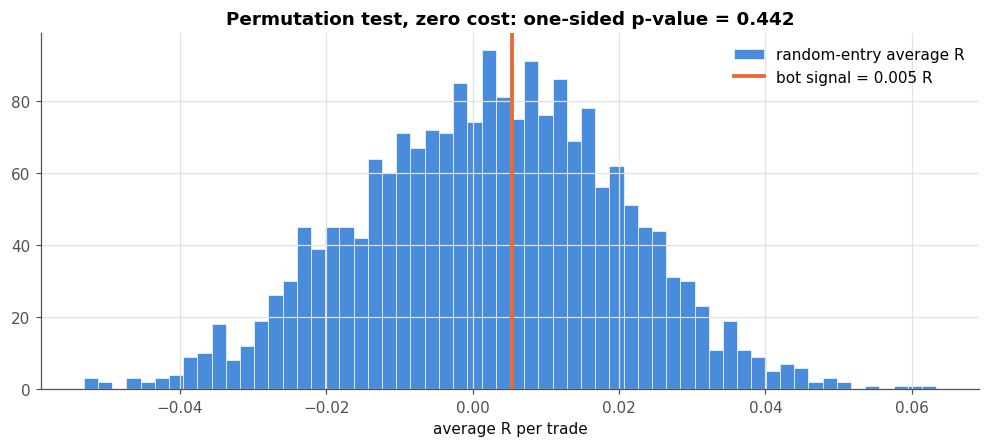

observed 0.0054 R, null mean 0.0022 R, null 95th pct 0.0304 R, p-value 0.442


In [11]:
pool_n = 30000
pool_idx = rng.choice(np.arange(200, len(ind) - 1), pool_n, replace=False)
pool_dir = rng.choice([-1, 1], pool_n)
atr_arr = ind.atr.to_numpy(); t_next = ind.time.to_numpy()
js = np.searchsorted(ex.t, t_next[pool_idx + 1])
pool_R = np.array([(lambda r: (r[2] - r[1]) * d / r[4])(ex.solve(j, d, atr_arr[i], P0, 0.0))
                   for i, j, d in zip(pool_idx, js, pool_dir)])
n_tr, buys = len(raw0), (raw0.dir > 0).sum()
pool_b, pool_s = pool_R[pool_dir > 0], pool_R[pool_dir < 0]
null = np.array([np.r_[rng.choice(pool_b, buys), rng.choice(pool_s, n_tr - buys)].mean() for _ in range(2000)])
obs = raw0.R.mean()
p_val = (null >= obs).mean()
fig, ax = plt.subplots()
ax.hist(null, bins=60, color=C1, alpha=0.85, edgecolor="white", linewidth=0.5, label="random-entry average R")
ax.axvline(obs, color=C2, lw=2.5, label=f"bot signal = {obs:.3f} R")
ax.set_title(f"Permutation test, zero cost: one-sided p-value = {p_val:.3f}"); ax.set_xlabel("average R per trade")
ax.legend(); plt.show()
print(f"observed {obs:.4f} R, null mean {null.mean():.4f} R, null 95th pct {np.percentile(null, 95):.4f} R, p-value {p_val:.3f}")

## 5. Where it wins and where it loses (spread 0.30, R per trade)

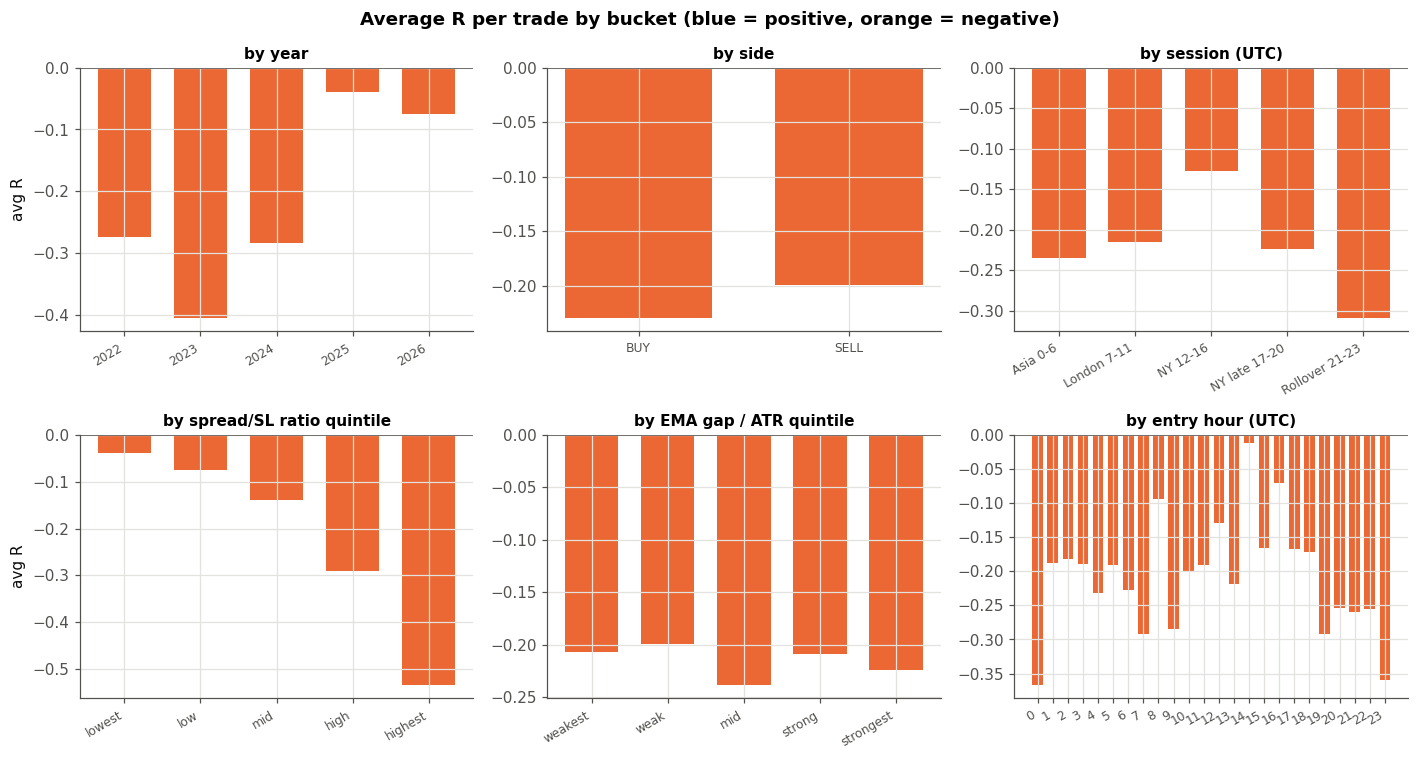

,trades,avg_R,win_pct,spread_to_SL
cost_bucket,,,,
lowest,1035,-0.038,38.744,0.056
low,1034,-0.076,36.460,0.107
mid,1034,-0.139,34.333,0.186
high,1034,-0.291,28.627,0.268
highest,1034,-0.535,18.762,0.410


In [12]:
r = raw.copy()
r["year"] = r.entry_time.dt.year
r["side"] = np.where(r.dir > 0, "BUY", "SELL")
r["hour"] = r.entry_time.dt.hour
r["session"] = pd.cut(r.hour, [-1, 6, 11, 16, 20, 23], labels=["Asia 0-6", "London 7-11", "NY 12-16", "NY late 17-20", "Rollover 21-23"])
r["cost_ratio"] = SPREAD / r.sl_dist
r["cost_bucket"] = pd.qcut(r.cost_ratio, 5, labels=["lowest", "low", "mid", "high", "highest"])
strength = (np.abs(ind.ema_fast - ind.ema_slow) / ind.atr).to_numpy()
ent_i = np.searchsorted(ind.time.to_numpy(), r.entry_time.to_numpy()) - 1
r["trend_bucket"] = pd.qcut(strength[ent_i], 5, labels=["weakest", "weak", "mid", "strong", "strongest"])
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for ax, col, title in zip(axs.flat, ["year", "side", "session", "cost_bucket", "trend_bucket", "hour"],
                          ["by year", "by side", "by session (UTC)", "by spread/SL ratio quintile", "by EMA gap / ATR quintile", "by entry hour (UTC)"]):
    g = r.groupby(col, observed=True)["R"].mean()
    ax.bar(range(len(g)), g.values, color=[C1 if v >= 0 else C2 for v in g.values], width=0.7)
    ax.set_xticks(range(len(g)), g.index.astype(str), rotation=30 if len(g) > 4 else 0, ha="right" if len(g) > 4 else "center", fontsize=8)
    ax.axhline(0, color=MUTED, lw=1); ax.set_title(title, fontsize=10)
axs[0, 0].set_ylabel("avg R"); axs[1, 0].set_ylabel("avg R")
fig.suptitle("Average R per trade by bucket (blue = positive, orange = negative)", fontweight="bold"); fig.tight_layout(); plt.show()
r.groupby("cost_bucket", observed=True).agg(trades=("R", "size"), avg_R=("R", "mean"), win_pct=("R", lambda x: 100 * (x > 0).mean()),
                                         spread_to_SL=("cost_ratio", "median")).round(3)

In [13]:
r0 = raw0.copy(); r0["year"] = r0.entry_time.dt.year
pd.DataFrame({"avg_R_zero_cost": r0.groupby("year").R.mean(), "avg_R_spread_0.30": r.groupby("year").R.mean(),
              "trades": r.groupby("year").R.size()}).round(3)

,avg_R_zero_cost,avg_R_spread_0.30,trades
year,,,
2022,0.007,-0.274,1138
2023,-0.033,-0.405,931
2024,-0.018,-0.284,1103
2025,0.067,-0.040,1049
2026,-0.001,-0.075,950


## 6. Parameter sensitivity surfaces

A robust edge shows a broad plateau of positive results around the chosen parameters, not one lucky
cell. Average R per trade at spread 0.30.

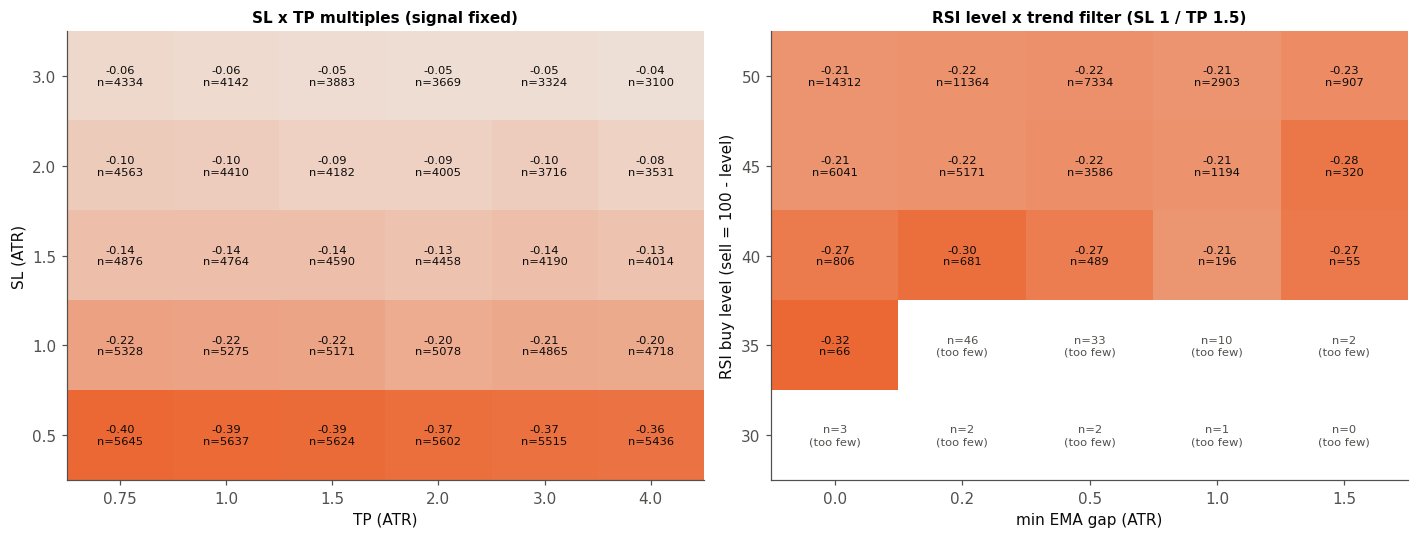

Cells with fewer than 50 trades are greyed out: RSI 30/35 + a strong trend filter almost never fires in an uptrend.


In [14]:
def heat(ax, cells, xs, ys, xl, yl, title, min_n=50):
    # cells: 2D list of summary dicts; cells with fewer than min_n trades are greyed out (too few to read)
    mat = np.array([[c["avg"] if c["trades"] >= min_n else np.nan for c in row] for row in cells])
    lim = max(0.05, np.nanmax(np.abs(mat)))
    im = ax.imshow(mat, cmap=DIV, vmin=-lim, vmax=lim, origin="lower", aspect="auto")
    ax.set_xticks(range(len(xs)), xs); ax.set_yticks(range(len(ys)), ys); ax.set_xlabel(xl); ax.set_ylabel(yl)
    for a, row in enumerate(cells):
        for b, c in enumerate(row):
            txt = f"{c['avg']:+.2f}\nn={c['trades']}" if c["trades"] >= min_n else f"n={c['trades']}\n(too few)"
            ax.text(b, a, txt, ha="center", va="center", fontsize=7.5, color=INK if c["trades"] >= min_n else MUTED)
    ax.grid(False); ax.set_title(title, fontsize=10); return im

sls, tps = [0.5, 1.0, 1.5, 2.0, 3.0], [0.75, 1.0, 1.5, 2.0, 3.0, 4.0]
c_sltp = [[E.summary(E.run_raw(ind, sig0, ex, E.Params(sl_atr=a, tp_atr=b), SPREAD)) for b in tps] for a in sls]
levels, trends = [30, 35, 40, 45, 50], [0.0, 0.2, 0.5, 1.0, 1.5]
c_rsi = [[E.summary(E.run_raw(ind, E.signals(ind, E.Params(rsi_buy=lv, rsi_sell=100 - lv, min_trend_atr=tt), SPREAD), ex, P0, SPREAD))
          for tt in trends] for lv in levels]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
heat(axs[0], c_sltp, tps, sls, "TP (ATR)", "SL (ATR)", "SL x TP multiples (signal fixed)")
heat(axs[1], c_rsi, trends, levels, "min EMA gap (ATR)", "RSI buy level (sell = 100 - level)", "RSI level x trend filter (SL 1 / TP 1.5)")
fig.tight_layout(); plt.show()
print("Cells with fewer than 50 trades are greyed out: RSI 30/35 + a strong trend filter almost never fires in an uptrend.")

In [15]:
# timeframe: same rules on M15 and H1 bars (bigger ATR, so the spread is a smaller share of 1R)
tf_rows = []
for tf in ["5min", "15min", "30min", "1h"]:
    b = E.add_htf(E.indicators(E.resample(m1, tf), P0), m1); s_ = E.signals(b, P0, SPREAD)
    for sp in [0.0, SPREAD]:
        sm = E.summary(E.run_raw(b, s_, ex, P0, sp)); sm.update(timeframe=tf, spread=sp); tf_rows.append(sm)
pd.DataFrame(tf_rows).set_index(["timeframe", "spread"])[["trades", "win_pct", "avg", "total", "pf", "t_stat"]].round(3)

trades  win_pct    avg     total     pf  t_stat
timeframe spread                                                 
5min      0.0       4936   40.174  0.005    26.743  1.009   0.306
          0.3       5171   31.387 -0.216 -1115.309  0.687 -13.166
15min     0.0       1639   40.390 -0.000    -0.629  0.999  -0.012
          0.3       1670   36.407 -0.103  -171.558  0.843  -3.270
30min     0.0        849   40.400  0.003     2.787  1.005   0.077
          0.3        862   36.311 -0.098   -84.678  0.847  -2.377
1h        0.0        405   38.519 -0.032   -13.141  0.948  -0.526
          0.3        408   37.010 -0.071   -29.116  0.888  -1.169

## 7. Walk-forward optimisation

Grid of 72 variants (timeframe M5/M15/H1, SL/TP pair, RSI level, trend filter, H1 trend filter).
Rolling windows: optimise on the previous 12 months (best average R with at least 30 trades), trade the
chosen variant on the next 3 months, roll forward. The stitched out-of-sample curve is what a trader
re-optimising every quarter would have earned. Spread 0.30.

In [16]:
import itertools
frames = {tf: E.add_htf(E.indicators(E.resample(m1, tf), P0), m1) for tf in ["5min", "15min", "1h"]}
grid = list(itertools.product(["5min", "15min", "1h"], [(1.0, 1.5), (1.5, 3.0), (2.0, 2.0)], [40, 45],
                              [0.2, 0.8], [False, True]))
trials = {}
t0 = time.time()
for tf, (sl, tp), lv, tt, htf in grid:
    p = E.Params(rsi_buy=lv, rsi_sell=100 - lv, min_trend_atr=tt, sl_atr=sl, tp_atr=tp, htf_filter=htf)
    trials[(tf, sl, tp, lv, tt, htf)] = E.run_raw(frames[tf], E.signals(frames[tf], p, SPREAD), ex, p, SPREAD)
print(f"{len(trials)} variants simulated in {time.time()-t0:.0f}s")
full = pd.DataFrame({k: E.summary(v) for k, v in trials.items()}).T
full.index.names = ["tf", "sl", "tp", "rsi", "trend", "htf"]
print("(variants with fewer than 100 trades, e.g. H1 + RSI 40 + H1 filter, are degenerate and excluded from rankings)")
full = full[full.trades >= 100]
print("variants (>= 100 trades) with positive full-period average R after costs:", int((full["avg"] > 0).sum()), "of", len(full))
full.sort_values("avg", ascending=False).head(10)[["trades", "win_pct", "avg", "total", "pf", "t_stat"]].round(3)

72 variants simulated in 1s
(variants with fewer than 100 trades, e.g. H1 + RSI 40 + H1 filter, are degenerate and excluded from rankings)
variants (>= 100 trades) with positive full-period average R after costs: 0 of 60


trades  win_pct    avg   total     pf  t_stat
tf    sl  tp  rsi trend htf                                                 
15min 2.0 2.0 40  0.2   True    240.0   50.417 -0.002  -0.514  0.996  -0.032
                        False   267.0   50.187 -0.006  -1.514  0.989  -0.091
              45  0.8   True    567.0   49.735 -0.009  -5.373  0.981  -0.221
                        False   587.0   49.574 -0.013  -7.373  0.975  -0.298
      1.5 3.0 40  0.8   False   139.0   33.094 -0.019  -2.618  0.972  -0.155
      2.0 2.0 40  0.8   False   139.0   48.921 -0.025  -3.475  0.951  -0.293
              45  0.2   True   1119.0   49.062 -0.025 -28.279  0.952  -0.817
              40  0.8   True    137.0   48.905 -0.025  -3.475  0.951  -0.295
      1.5 3.0 40  0.8   True    137.0   32.847 -0.026  -3.618  0.961  -0.217
1h    1.0 1.5 45  0.8   False   185.0   38.919 -0.029  -5.359  0.953  -0.322

In [17]:
starts = pd.date_range("2023-01-01", "2026-10-01", freq="3MS")
wf_parts, picks = [], []
for s0 in starts:
    is_lo, is_hi, oos_hi = s0 - pd.DateOffset(months=12), s0, s0 + pd.DateOffset(months=3)
    best, best_avg, best_is = None, -np.inf, None
    for k, tr in trials.items():
        w = tr[(tr.entry_time >= is_lo) & (tr.entry_time < is_hi)]
        if len(w) >= 30 and w.R.mean() > best_avg: best, best_avg = k, w.R.mean()
    tr = trials[best]; o = tr[(tr.entry_time >= is_hi) & (tr.entry_time < oos_hi)].copy()
    o["variant"] = str(best); wf_parts.append(o)
    picks.append(dict(oos_start=s0.date(), variant=best, is_avg_R=best_avg, oos_avg_R=o.R.mean(), oos_trades=len(o)))
wf = pd.concat(wf_parts).sort_values("exit_time"); picks = pd.DataFrame(picks)
wfe = picks.oos_avg_R.mean() / picks.is_avg_R.mean()
print(f"walk-forward OOS: {E.summary(wf)}")
print(f"walk-forward efficiency (OOS avg R / IS avg R): {wfe:.2f}")
picks.round(3)

walk-forward OOS: {'trades': 248, 'win_pct': 35.483870967741936, 'avg': 0.01316300224979501, 'total': 3.2644245579491624, 'pf': 1.020183713750218, 'max_dd': -26.01718123225746, 't_stat': 0.1483300344552752}
walk-forward efficiency (OOS avg R / IS avg R): 0.04


,oos_start,variant,is_avg_R,oos_avg_R,oos_trades
0,2023-01-01,"(15min, 2.0, 2.0, 40, 0.8, True)",0.333,-0.211,7
1,2023-04-01,"(1h, 1.5, 3.0, 45, 0.8, False)",0.049,-0.250,4
2,2023-07-01,"(1h, 1.5, 3.0, 45, 0.8, False)",0.085,0.651,9
3,2023-10-01,"(15min, 2.0, 2.0, 40, 0.8, False)",0.110,-0.091,11
4,2024-01-01,"(1h, 1.5, 3.0, 45, 0.2, False)",0.239,-0.062,16
5,2024-04-01,"(15min, 1.0, 1.5, 40, 0.8, False)",0.328,-0.444,9
6,2024-07-01,"(1h, 1.5, 3.0, 45, 0.2, False)",0.241,-0.400,20
7,2024-10-01,"(1h, 1.0, 1.5, 45, 0.2, False)",0.067,-0.231,13
8,2025-01-01,"(5min, 1.5, 3.0, 40, 0.8, True)",0.125,-0.077,13
9,2025-04-01,"(5min, 1.5, 3.0, 40, 0.8, True)",0.188,0.250,12


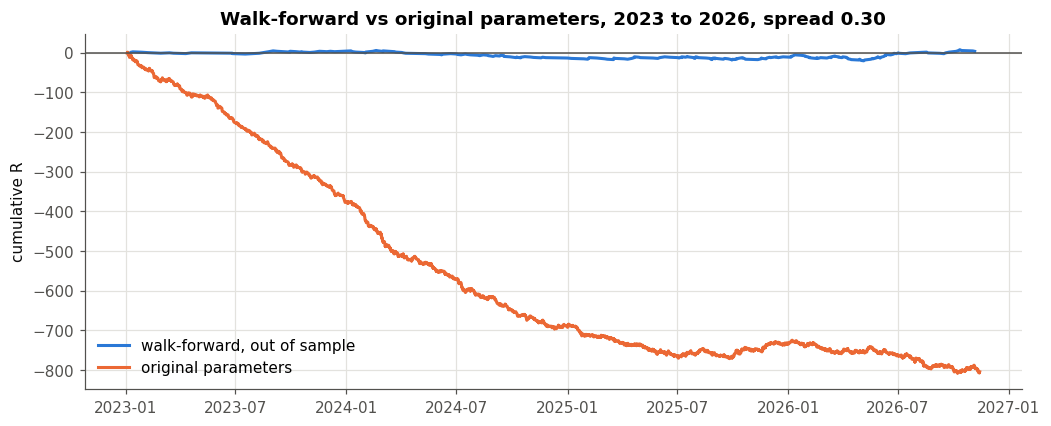

In [18]:
fig, ax = plt.subplots()
ax.plot(wf.exit_time, wf.R.cumsum(), color=C1, label="walk-forward, out of sample")
base = trials[("5min", 1.0, 1.5, 45, 0.2, False)]; base = base[base.entry_time >= "2023-01-01"]
ax.plot(base.exit_time, base.R.cumsum(), color=C2, label="original parameters")
ax.axhline(0, color=MUTED, lw=1); ax.set_ylabel("cumulative R"); ax.set_title("Walk-forward vs original parameters, 2023 to 2026, spread 0.30")
ax.legend(); plt.show()

## 8. Monte Carlo on the trade sequence

Bootstrap (resampling the bot-replay trades with replacement, 10,000 paths of the same length) to see the
range of outcomes and drawdowns the same edge could have produced, and a reshuffle to separate luck of
ordering from the edge itself.

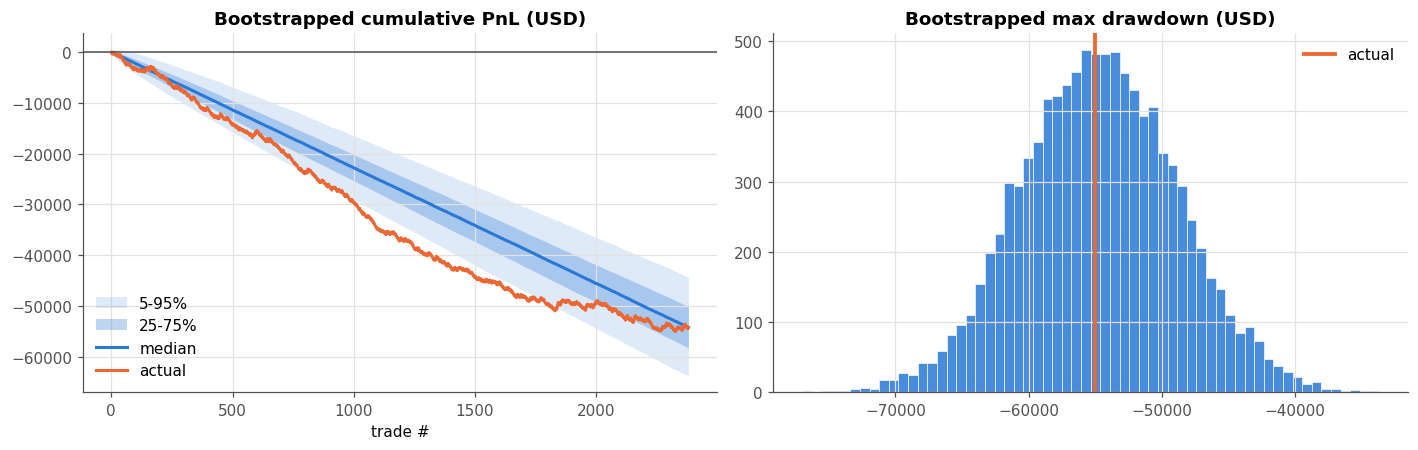

P(final PnL > 0) = 0.00%
final PnL 5/50/95 pct: [-63752. -54224. -44320.]
max drawdown 5/50/95 pct: [-64231. -54773. -45039.]
P(drawdown worse than 20% of 100k) = 100.00%


In [19]:
pnl = bt.pnl.to_numpy(); n = len(pnl); N = 10000
boot = rng.choice(pnl, (N, n), replace=True).cumsum(axis=1)
boot_dd = (boot - np.maximum.accumulate(np.c_[np.zeros(N), boot], axis=1)[:, 1:]).min(axis=1)
shuf = np.array([rng.permutation(pnl).cumsum() for _ in range(2000)])
shuf_dd = (shuf - np.maximum.accumulate(np.c_[np.zeros(2000), shuf], axis=1)[:, 1:]).min(axis=1)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(1, n + 1)
q = np.percentile(boot, [5, 25, 50, 75, 95], axis=0)
axs[0].fill_between(x, q[0], q[4], color=C1, alpha=0.15, lw=0, label="5-95%")
axs[0].fill_between(x, q[1], q[3], color=C1, alpha=0.3, lw=0, label="25-75%")
axs[0].plot(x, q[2], color=C1, label="median"); axs[0].plot(x, pnl.cumsum(), color=C2, label="actual")
axs[0].axhline(0, color=MUTED, lw=1); axs[0].set_title("Bootstrapped cumulative PnL (USD)"); axs[0].set_xlabel("trade #"); axs[0].legend()
axs[1].hist(boot_dd, bins=60, color=C1, alpha=0.85, edgecolor="white", linewidth=0.5)
axs[1].axvline((pnl.cumsum() - np.maximum.accumulate(np.r_[0, pnl.cumsum()])[1:]).min(), color=C2, lw=2.5, label="actual")
axs[1].set_title("Bootstrapped max drawdown (USD)"); axs[1].legend(); fig.tight_layout(); plt.show()
print(f"P(final PnL > 0) = {(boot[:, -1] > 0).mean():.2%}")
print(f"final PnL 5/50/95 pct: {np.percentile(boot[:, -1], [5, 50, 95]).round(0)}")
print(f"max drawdown 5/50/95 pct: {np.percentile(boot_dd, [5, 50, 95]).round(0)}")
print(f"P(drawdown worse than 20% of 100k) = {(boot_dd < -20000).mean():.2%}")

In [20]:
# Same bootstrap on the best walk-forward OOS R stream: is there any setting with a reliably positive path?
w = wf.R.to_numpy(); bw = rng.choice(w, (N, len(w)), replace=True)
print(f"walk-forward OOS: mean R {w.mean():.3f}, P(total R > 0) = {(bw.sum(axis=1) > 0).mean():.2%}, "
      f"95% CI of mean R = [{np.percentile(bw.mean(axis=1), 2.5):.3f}, {np.percentile(bw.mean(axis=1), 97.5):.3f}]")

walk-forward OOS: mean R 0.013, P(total R > 0) = 55.52%, 95% CI of mean R = [-0.160, 0.189]


## 9. Stress tests (raw signal, original parameters, R per trade)

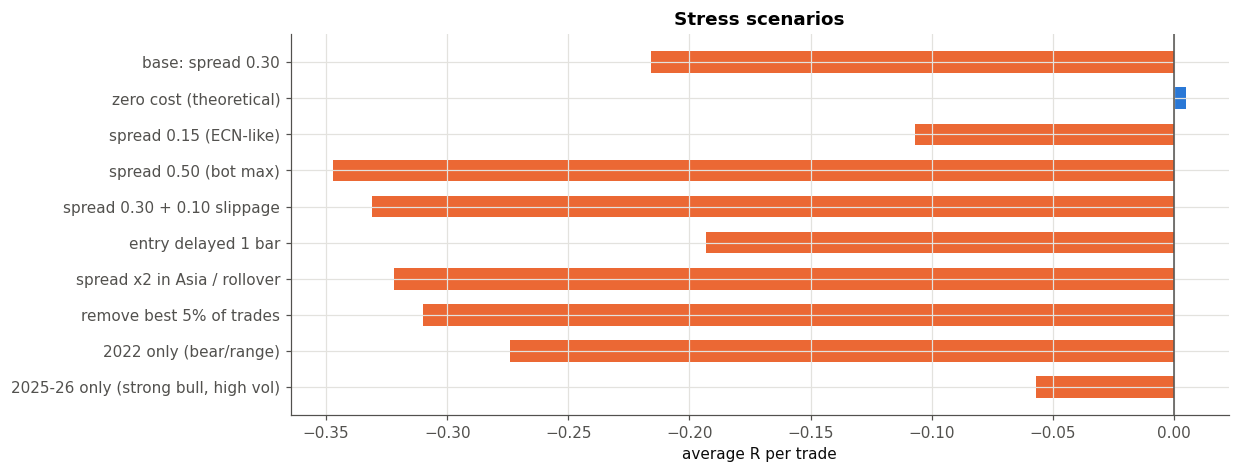

,trades,win_pct,avg,total,pf,max_dd,t_stat
scenario,,,,,,,
base: spread 0.30,5171,31.387,-0.216,-1115.309,0.687,-1118.809,-13.166
zero cost (theoretical),4936,40.174,0.005,26.743,1.009,-83.584,0.306
spread 0.15 (ECN-like),5051,35.716,-0.107,-538.911,0.835,-570.048,-6.231
spread 0.50 (bot max),5284,26.173,-0.347,-1832.508,0.532,-1835.508,-22.688
spread 0.30 + 0.10 slippage,5230,28.948,-0.331,-1733.241,0.569,-1736.241,-20.194
entry delayed 1 bar,5005,32.288,-0.193,-965.933,0.716,-983.446,-11.562
spread x2 in Asia / rollover,5251,27.119,-0.322,-1690.580,0.560,-1715.551,-20.677
remove best 5% of trades,4913,27.783,-0.310,-1521.440,0.574,-1524.440,-19.257
2022 only (bear/range),1138,28.998,-0.274,-311.399,0.615,-313.399,-8.105


In [21]:
st = []
def add(name, tr): sm = E.summary(tr); sm["scenario"] = name; st.append(sm)
add("base: spread 0.30", raw)
add("zero cost (theoretical)", raw0)
add("spread 0.15 (ECN-like)", E.run_raw(ind, sig0, ex, P0, 0.15))
add("spread 0.50 (bot max)", E.run_raw(ind, sig0, ex, P0, 0.50))
add("spread 0.30 + 0.10 slippage", E.run_raw(ind, sig0, ex, P0, SPREAD, slip=0.10))
add("entry delayed 1 bar", E.run_raw(ind, sig0, ex, P0, SPREAD, delay_bars=1))
add("spread x2 in Asia / rollover", pd.concat([raw[~raw.entry_time.dt.hour.isin(list(range(0, 7)) + [21, 22, 23])],
                                               E.run_raw(ind, sig0, ex, P0, 2 * SPREAD).pipe(lambda d: d[d.entry_time.dt.hour.isin(list(range(0, 7)) + [21, 22, 23])])]))
top = raw.R.nlargest(int(0.05 * len(raw))).index
add("remove best 5% of trades", raw.drop(top))
add("2022 only (bear/range)", raw[raw.entry_time.dt.year == 2022])
add("2025-26 only (strong bull, high vol)", raw[raw.entry_time.dt.year >= 2025])
stress = pd.DataFrame(st).set_index("scenario")[["trades", "win_pct", "avg", "total", "pf", "max_dd", "t_stat"]].round(3)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(stress.index[::-1], stress["avg"][::-1], color=[C1 if v >= 0 else C2 for v in stress["avg"][::-1]], height=0.6)
ax.axvline(0, color=MUTED, lw=1); ax.set_xlabel("average R per trade"); ax.set_title("Stress scenarios"); plt.show()
stress

## 10. Probabilistic and Deflated Sharpe

PSR = probability that the true per-trade Sharpe is above 0, given sample size, skew and fat tails.
The Deflated Sharpe raises the bar to the Sharpe you would expect from the best of the 72 walk-forward
variants by pure chance (multiple-testing correction).

In [22]:
srs = np.array([v.R.mean() / v.R.std(ddof=1) for v in trials.values() if len(v) >= 100])
sr0 = E.expected_max_sr(len(srs), srs.var(ddof=1))
rows = []
for name, x in [("original, spread 0.30", raw.R), ("original, zero cost", raw0.R), ("walk-forward OOS", wf.R),
                ("best in-sample variant (full period)", trials[full["avg"].astype(float).idxmax()].R)]:
    p_, sr = E.psr(x); d_, _ = E.psr(x, sr0)
    rows.append(dict(series=name, trades=len(x), sharpe_per_trade=sr, PSR=p_, DSR=d_))
print(f"expected max Sharpe per trade from {len(srs)} skill-less trials: {sr0:.3f}")
pd.DataFrame(rows).set_index("series").round(3)

expected max Sharpe per trade from 60 skill-less trials: 0.142


,trades,sharpe_per_trade,PSR,DSR
series,,,,
"original, spread 0.30",5171,-0.183,0.000,0.000
"original, zero cost",4936,0.004,0.620,0.000
walk-forward OOS,248,0.009,0.559,0.019
best in-sample variant (full period),240,-0.002,0.487,0.013


## 11. Gaps found in the indicator and the code

**Edge and design**
1. **No predictive edge in the entry.** Before costs the signal averages about 0 R per trade, the same
   as random entries with the same exits (sections 3 and 4). An EMA20/50 trend plus an RSI 45/55 pullback
   on M5 gold is a widely used pattern and the market prices it in.
2. **The stop is too small relative to costs.** SL = 1 M5 ATR is only about 1 to 5 USD, so a 0.30 spread
   is often 10 to 30% of the risk. Every trade starts at about -0.2 R. This one factor turns a flat
   signal into a steadily losing one (section 3, cost buckets in section 5).
3. **RSI 45/55 crosses are noise on M5.** The "pullback is over" trigger fires about 1,000 times a year.
   Sensitivity surfaces (section 6) show no plateau of positive cells: the result changes sign with
   small parameter changes, which is a sign of fitting noise, not structure.
4. **No regime, session or higher-timeframe context.** It trades Asia, rollover (21:00 to 23:00 UTC, the
   widest spreads) and against the H1 trend just the same.
5. **Fixed 1.5 R target, no trailing, no time stop.** Exits are symmetric brackets; nothing lets winners
   run in the trending regime the filter is meant to catch.

**Risk rules**
6. **Risk is set by the 180 USD daily cap, not by `RISK_PERCENT`.** On 100k equity, 0.5% = 500 USD, but
   the cap gives about 90 USD per trade (0.09%). The percentage parameter is effectively dead.
7. **The daily loss check only runs when a new signal appears.** `CLOSE_ALL_ON_LIMIT` does not fire while
   no signal is printed, and an intraday loss that is only floating is not watched between signals.
8. **`halted_today` uses the PC date (`dt.date.today()`) while the loss is counted on the broker
   server day.** Around midnight the two disagree, so the halt can carry over or reset early.
9. **The weekly target stops trading after a good week.** It adds no edge and cuts off the right tail;
   it only makes sense if the edge decays within a week, which nothing here shows.
10. **`test_trade.py` uses the same `MAGIC_NUMBER` (123456)**, so a test trade counts against the bot's
    daily trade limit and PnL.

**Code and operations**
11. **Secrets are committed.** `.env` (Telegram token, chat id, Gemini key) is tracked in git and pushed to
    a public GitHub repo, and `test_telegram.py` / `test_trade.py` hardcode Telegram tokens. Rotate all
    of them now. Removing the files alone is not enough because they stay in the git history.
12. **Gemini filter is fail-open and not testable.** A yes/no from an LLM on five numbers adds latency
    and randomness at entry; with no key or on error it lets the trade through anyway.
13. **The journal CSV has a header with 8 columns but rows with 9** (the `Risque` column was added
    later), and the README says `.env` is never sent to GitHub while it is.
14. `lancer.bat` hardcodes `C:\bot`; there is no `.gitignore`; `bot.log` comes from an older M15 version.

## 12. Improvement research with an untouched holdout

Discipline: candidate fixes are chosen on **2022-01 to 2024-12 (in-sample)** only, and checked **once**
on **2025-01 to 2026-11 (holdout)**. Each candidate addresses one gap above.

In [23]:
IS_END = pd.Timestamp("2025-01-01")
def evaluate(name, frame, p):
    tr = E.run_raw(frame, E.signals(frame, p, SPREAD), ex, p, SPREAD)
    a, b = tr[tr.entry_time < IS_END], tr[tr.entry_time >= IS_END]
    sa, sb = E.summary(a), E.summary(b)
    return dict(candidate=name, IS_trades=sa.get("trades", 0), IS_avg_R=sa.get("avg", np.nan), IS_t=sa.get("t_stat", np.nan),
                HO_trades=sb.get("trades", 0), HO_avg_R=sb.get("avg", np.nan), HO_t=sb.get("t_stat", np.nan)), tr
LONDON_NY = tuple(range(7, 17))
cands = [
    ("0. original (M5)", frames["5min"], P0),
    ("1. London+NY hours only", frames["5min"], E.Params(hours_utc=LONDON_NY)),
    ("2. + H1 trend filter", frames["5min"], E.Params(hours_utc=LONDON_NY, htf_filter=True)),
    ("3. + ATR >= 10 spreads", frames["5min"], E.Params(hours_utc=LONDON_NY, htf_filter=True, min_atr_spreads=10)),
    ("4. M15, SL 1.5 / TP 3", frames["15min"], E.Params(sl_atr=1.5, tp_atr=3.0)),
    ("5. M15, SL 1.5 / TP 3, hours + H1", frames["15min"], E.Params(sl_atr=1.5, tp_atr=3.0, hours_utc=LONDON_NY, htf_filter=True)),
    ("6. H1, SL 1.5 / TP 3", frames["1h"], E.Params(sl_atr=1.5, tp_atr=3.0)),
    ("7. H1, SL 2 / TP 4, H1 trend", frames["1h"], E.Params(sl_atr=2.0, tp_atr=4.0, htf_filter=True)),
    ("8. H1, SL 2 / TP 4, trend >= 0.8", frames["1h"], E.Params(sl_atr=2.0, tp_atr=4.0, min_trend_atr=0.8)),
]
res, curves = [], {}
for name, fr, p in cands:
    row, tr = evaluate(name, fr, p); res.append(row); curves[name] = tr
imp = pd.DataFrame(res).set_index("candidate").round(3)
imp

,IS_trades,IS_avg_R,IS_t,HO_trades,HO_avg_R,HO_t
candidate,,,,,,
0. original (M5),3172,-0.316,-15.711,1999,-0.057,-2.060
1. London+NY hours only,1258,-0.241,-7.265,837,-0.072,-1.697
2. + H1 trend filter,924,-0.177,-4.465,643,-0.092,-1.883
3. + ATR >= 10 spreads,64,0.055,0.352,476,-0.104,-1.825
"4. M15, SL 1.5 / TP 3",831,-0.165,-3.376,541,0.064,1.011
"5. M15, SL 1.5 / TP 3, hours + H1",349,-0.169,-2.160,208,0.126,1.235
"6. H1, SL 1.5 / TP 3",211,-0.022,-0.225,138,-0.219,-1.913
"7. H1, SL 2 / TP 4, H1 trend",60,-0.202,-1.170,52,0.023,0.112
"8. H1, SL 2 / TP 4, trend >= 0.8",87,-0.105,-0.709,65,0.003,0.015


Chosen on in-sample only: 3. + ATR >= 10 spreads
  in-sample : 64 trades, avg R +0.055, t = 0.35
  holdout   : 476 trades, avg R -0.104, t = -1.82


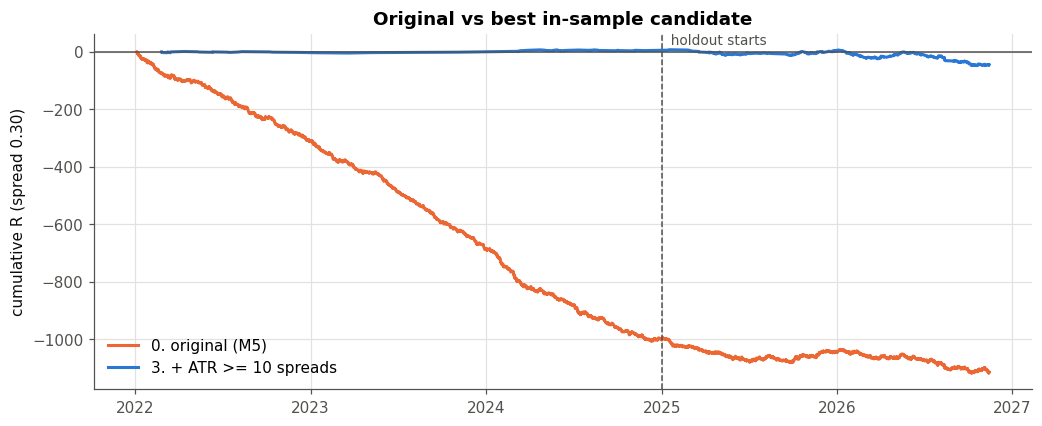

In [24]:
best_is = imp["IS_avg_R"].idxmax()
print(f"Chosen on in-sample only: {best_is}")
print(f"  in-sample : {imp.loc[best_is, 'IS_trades']} trades, avg R {imp.loc[best_is, 'IS_avg_R']:+.3f}, t = {imp.loc[best_is, 'IS_t']:.2f}")
print(f"  holdout   : {imp.loc[best_is, 'HO_trades']} trades, avg R {imp.loc[best_is, 'HO_avg_R']:+.3f}, t = {imp.loc[best_is, 'HO_t']:.2f}")
fig, ax = plt.subplots()
for (name, col) in zip(["0. original (M5)", best_is], [C2, C1]):
    tr = curves[name]; ax.plot(tr.exit_time, tr.R.cumsum(), color=col, label=name)
ax.axvline(IS_END, color=MUTED, ls="--", lw=1); ax.text(IS_END, ax.get_ylim()[1], "  holdout starts", va="top", color=MUTED, fontsize=9)
ax.axhline(0, color=MUTED, lw=1); ax.set_ylabel("cumulative R (spread 0.30)"); ax.set_title("Original vs best in-sample candidate")
ax.legend(loc="lower left"); plt.show()

## 13. Conclusions

**Verdict: in its current form this is not a winning indicator, and none of the variants tested here
is one either.** The evidence is consistent across every test:

| Test | Result |
|---|---|
| Faithful bot replay, 2022 to 2026, spread 0.30 | 2,370 trades, 31% win rate, profit factor 0.67, about -53.6k USD on a 100k account, every year negative, 53 of 59 months negative |
| Edge before any cost | +0.005 R per trade (t = 0.3), the same as random entries with the same exits (+0.010 R) |
| Permutation test (2,000 random-entry sets) | p-value 0.44: the signal sits in the middle of the random-entry distribution, no timing skill |
| 72-variant grid (timeframe, SL/TP, RSI, trend, H1 filter) | 0 of the 60 variants with at least 100 trades is profitable after a 0.30 spread |
| Cost | the median spread is about 19% of the stop distance on M5, so each trade starts near -0.2 R |
| Parameter surfaces | no stable positive plateau; sign flips with small changes |
| Other timeframes (M15, M30, H1) | still about 0 R before costs |
| Walk-forward (72 variants, 12m in / 3m out) | +0.013 R per trade out of sample, t = 0.15, 95% CI [-0.16, +0.19], walk-forward efficiency 0.04 |
| Monte Carlo on the replay | 0% of 10,000 bootstrap paths end positive; median max drawdown about 54k |
| Deflated Sharpe | about 0 for every series once the number of variants tried is accounted for |
| Best in-sample improvement on the holdout | chosen on 2022-24 (+0.055 R), it lost on 2025-26 (-0.112 R) |

Why 2025-26 looks less bad: gold's M5 ATR went from about 1 USD to about 5 USD, so the fixed spread is
a smaller share of each stop. The signal did not get better; the cost got relatively smaller.

A note on candidates 4 and 5 (M15 with SL 1.5 / TP 3): they are positive on the holdout but negative
in-sample. Picking them now because of the holdout would be fitting on the holdout, so they are leads
for new research at most, not fixes.

**Recommendations**
1. Do not run this bot on a live account. Keep it on demo only, which is what `REQUIRE_DEMO` already enforces.
2. Rotate the Telegram bot token and the Gemini API key now, remove `.env` and the hardcoded tokens
   from the repo, and add a `.gitignore`. They stay in the public git history until the history is rewritten.
3. Fix the code-level gaps (section 11, items 6 to 10, 12 and 13), even for demo use, so the bot does
   what its README says.
4. For a new strategy, start from a hypothesis with a reason to work and keep total cost below about
   5% of 1R (H1 or higher, wider ATR stops). Validate it with the same pipeline:
   in-sample selection, one untouched holdout, walk-forward, permutation test, Deflated Sharpe.

Limits of this study: HistData bid quotes with a modelled fixed spread (not real broker ticks); broker
server day assumed UTC+2; the Gemini filter is not simulated; SL and TP inside one M1 bar assume SL
first (2 cases out of 2,370).